# GIS Programming - ESI SBA 2026-2027
## Lab 4: GeoPandas Vector Data Fundamentals

**How to run on Google Colab:** open this file in Colab, then use **Runtime > Run all**.
An internet connection is required (the data is downloaded from GADM).
At the very end, a cell zips the `output/` folder so you can download all generated files.

**Quick glossary used in this lab**
- **GeoDataFrame**: a pandas DataFrame with a special `geometry` column (points, lines, polygons).
- **CRS** (Coordinate Reference System): how coordinates map to the Earth. `EPSG:4326` = latitude/longitude in degrees; `EPSG:326xx` (UTM) = metres, which is what you need to compute areas.

## Setup
The first cell checks which libraries are missing and installs only those (Colab already ships with geopandas, so normally nothing is installed).

In [2]:
import importlib.util, subprocess, sys

needed = ["geopandas", "pyogrio", "shapely", "matplotlib", "pandas", "numpy", "requests"]
missing = [p for p in needed if importlib.util.find_spec(p) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [3]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point, Polygon, LineString, box
from shapely.ops import unary_union
import os, io, time, requests

# Create output directory for saved files
os.makedirs("output", exist_ok=True)

print("All libraries imported successfully!")
print(f"GeoPandas version: {gpd.__version__}")

All libraries imported successfully!
GeoPandas version: 1.2.0


### Helper functions (small utilities used later)
- `load_gadm(url)`: downloads a GADM file, retrying a few times and falling back to `requests` if the direct read fails (the server is sometimes slow).
- `list_layers(path)`: lists the layers inside a GeoPackage. It uses `pyogrio` (the default engine in recent GeoPandas) and falls back to `fiona`.

In [4]:
def load_gadm(url, retries=3):
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            return gpd.read_file(url)
        except Exception as e:
            last_err = e
            print(f"Attempt {attempt} failed: {e}")
            time.sleep(2)
    # Fallback: download the raw file with requests, then parse it from memory
    try:
        r = requests.get(url, timeout=180, headers={"User-Agent": "Mozilla/5.0"})
        r.raise_for_status()
        return gpd.read_file(io.BytesIO(r.content))
    except Exception as e:
        raise RuntimeError(f"Could not download {url}. Last error: {last_err} | fallback error: {e}")


def list_layers(path):
    try:
        import pyogrio
        return [row[0] for row in pyogrio.list_layers(path)]
    except Exception:
        import fiona
        return fiona.listlayers(path)

print("Helpers defined.")

Helpers defined.


# Part A: Loading and Exploring Gaza Data

## Exercise A1: Load Gaza Governorates
`gpd.read_file(url)` reads a GeoJSON straight from the web into a GeoDataFrame.
GADM level 1 = first administrative division (governorates for Palestine).
The file contains the West Bank **and** Gaza, so we filter in A2.

In [5]:
# Load Palestine administrative boundaries (Level 1 = governorates)
palestine = load_gadm("https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_PSE_1.json")

print("=== Palestine Data Overview ===")
print(f"Shape: {palestine.shape}")
print(f"Columns: {list(palestine.columns)}")
print()
print(palestine[["NAME_1", "TYPE_1"]].to_string())

=== Palestine Data Overview ===
Shape: (2, 12)
Columns: ['GID_1', 'GID_0', 'COUNTRY', 'NAME_1', 'VARNAME_1', 'NL_NAME_1', 'TYPE_1', 'ENGTYPE_1', 'CC_1', 'HASC_1', 'ISO_1', 'geometry']

     NAME_1    TYPE_1
0      Gaza  District
1  WestBank  District


## Exercise A2: Filter to Gaza Strip Governorates
We select the 5 Gaza governorates by name. Because spelling can differ between GADM versions (e.g. "Deir el-Balah" vs "Deir Al-Balah"), the code tries three levels:
1. exact match (case-insensitive);
2. keyword match (`gaza`, `balah`, `khan`, `yunis`, `rafah`);
3. a geographic filter: governorates whose centroid falls inside the Gaza Strip bounding box.

In [6]:
gaza_names = ["North Gaza", "Gaza", "Deir el-Balah", "Khan Yunis", "Rafah"]
names_lower = palestine["NAME_1"].fillna("").str.lower()

# Level 1: exact names (case-insensitive)
gaza = palestine[names_lower.isin([n.lower() for n in gaza_names])].copy()

# Level 2: keyword match if spelling differs
if len(gaza) != 5:
    print(f"Exact-name filter found {len(gaza)} rows. Trying keyword filter...")
    keywords = ["gaza", "balah", "khan", "yunis", "rafah"]
    mask = names_lower.apply(lambda s: any(k in s for k in keywords))
    gaza = palestine[mask].copy()

# Level 3: geographic filter (centroids computed in a projected CRS to be accurate)
if len(gaza) != 5:
    print(f"Keyword filter found {len(gaza)} rows. Using geographic filter...")
    cent = palestine.to_crs("EPSG:32636").geometry.centroid.to_crs("EPSG:4326")
    mask = (cent.x.between(34.2, 34.6)) & (cent.y.between(31.2, 31.6))
    gaza = palestine[mask.values].copy()

gaza = gaza.reset_index(drop=True)

print(f"Number of Gaza governorates: {len(gaza)}")
print(f"Governorate names: {gaza['NAME_1'].tolist()}")

Exact-name filter found 1 rows. Trying keyword filter...
Keyword filter found 1 rows. Using geographic filter...
Number of Gaza governorates: 1
Governorate names: ['Gaza']


## Exercise A3: Inspect the Gaza GeoDataFrame
Basic inspection: shape, column types, CRS, geometry types and `total_bounds`
(the bounding box `[minx, miny, maxx, maxy]` of all geometries).

In [7]:
print("=== Gaza GeoDataFrame Inspection ===")
print()

# Shape
print(f"Shape (rows, columns): {gaza.shape}")
print()

# Columns and types
print("Column data types:")
print(gaza.dtypes)
print()

# CRS
print(f"CRS: {gaza.crs}")
print(f"CRS Name: {gaza.crs.name}")
print(f"EPSG Code: {gaza.crs.to_epsg()}")
print()

# Geometry types
print(f"Geometry types: {gaza.geom_type.unique()}")
print()

# Total bounds
minx, miny, maxx, maxy = gaza.total_bounds
print("Total bounds:")
print(f"  Min X (West):  {minx:.4f}")
print(f"  Min Y (South): {miny:.4f}")
print(f"  Max X (East):  {maxx:.4f}")
print(f"  Max Y (North): {maxy:.4f}")
print()

# Print all governorate names
print("All governorate names:")
for i, name in enumerate(gaza["NAME_1"].tolist(), 1):
    print(f"  {i}. {name}")

=== Gaza GeoDataFrame Inspection ===

Shape (rows, columns): (1, 12)

Column data types:
GID_1          object
GID_0          object
COUNTRY        object
NAME_1         object
VARNAME_1      object
NL_NAME_1      object
TYPE_1         object
ENGTYPE_1      object
CC_1           object
HASC_1         object
ISO_1          object
geometry     geometry
dtype: object

CRS: EPSG:4326
CRS Name: WGS 84
EPSG Code: 4326

Geometry types: ['MultiPolygon']

Total bounds:
  Min X (West):  34.2293
  Min Y (South): 31.2236
  Max X (East):  34.5463
  Max Y (North): 31.5944

All governorate names:
  1. Gaza


## Exercise A4: Calculate Area in km2
Areas must **not** be computed in degrees. We reproject to **UTM zone 36N (EPSG:32636)**, whose unit is the metre, compute `.geometry.area` (m2) and divide by 1,000,000 to get km2.

In [8]:
# Reproject to UTM Zone 36N (EPSG:32636) for accurate area calculation
gaza_utm = gaza.to_crs("EPSG:32636")

# Calculate area
gaza["area_m2"] = gaza_utm.geometry.area
gaza["area_km2"] = gaza["area_m2"] / 1e6

# Display areas
print("=== Gaza Governorate Areas ===")
print(gaza[["NAME_1", "area_km2"]].to_string(index=False))
print()
print(f"Total Gaza Strip area: {gaza['area_km2'].sum():.2f} km2")

=== Gaza Governorate Areas ===
NAME_1   area_km2
  Gaza 342.478123

Total Gaza Strip area: 342.48 km2


## Exercise A5: Find Centroids
The centroid is the geometric centre of a polygon. Computing it directly on lat/lon data gives a warning (degrees are not a flat plane), so we compute it in UTM and convert the result back to lat/lon for readability.

Note: we store the result as two plain number columns (`cen_lat`, `cen_lon`) instead of a second geometry column. A GeoDataFrame with two geometry columns cannot be saved to Shapefile/GeoJSON/GeoPackage in Part C, so this keeps the export working. The names are short (max 10 characters) because Shapefile truncates longer column names.

In [9]:
gaza_centroids = gaza_utm.geometry.centroid.to_crs("EPSG:4326")
gaza["cen_lat"] = gaza_centroids.y.values
gaza["cen_lon"] = gaza_centroids.x.values

print("=== Governorate Centroids ===")
for _, row in gaza.iterrows():
    print(f"{row['NAME_1']:20s} -> Lat: {row['cen_lat']:.4f}, Lon: {row['cen_lon']:.4f}")

=== Governorate Centroids ===
Gaza                 -> Lat: 31.4043, Lon: 34.3723


## Exercise A6: Plot Governorates with Labels
`GeoDataFrame.plot()` draws the polygons on a matplotlib axis; `ax.annotate()` writes each name at its centroid.

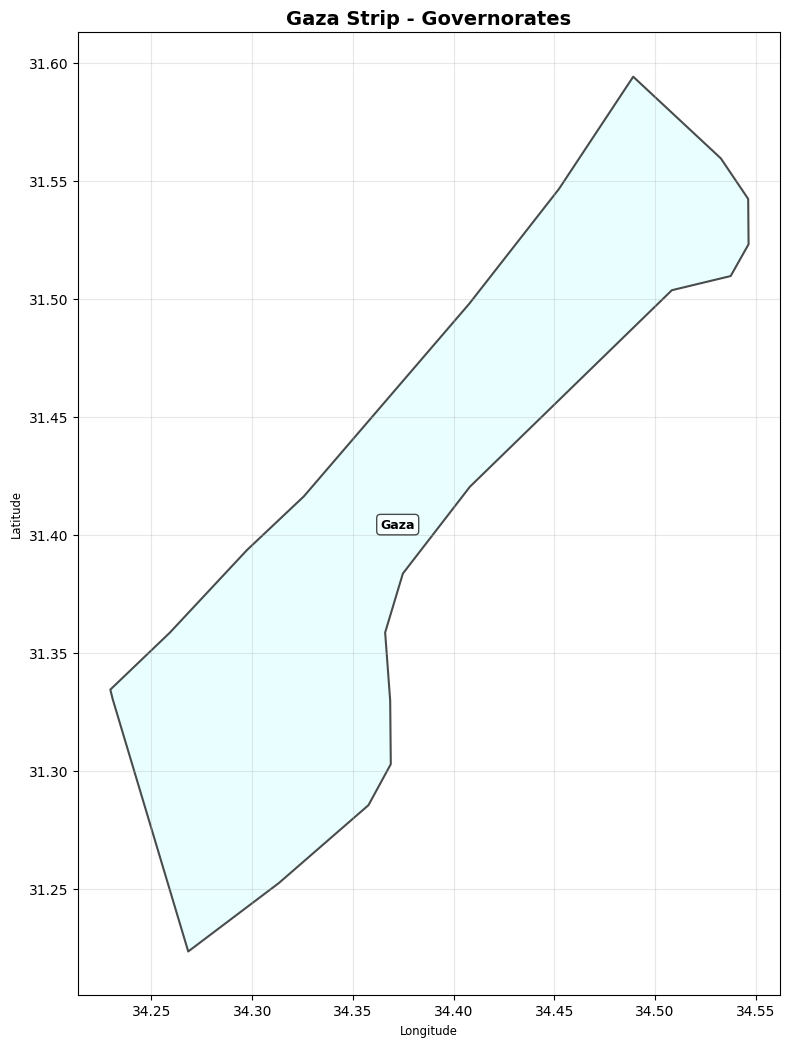

Plot saved to output/gaza_governorates.png


In [10]:
fig, ax = plt.subplots(figsize=(8, 12))

# Plot governorates
gaza.plot(
    ax=ax,
    edgecolor='black',
    linewidth=1.5,
    facecolor='lightcyan',
    alpha=0.7
)

# Add labels at centroids
for _, row in gaza.iterrows():
    ax.annotate(
        row["NAME_1"],
        xy=(row["cen_lon"], row["cen_lat"]),
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7)
    )

ax.set_title("Gaza Strip - Governorates", fontsize=14, fontweight='bold')
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("output/gaza_governorates.png", dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved to output/gaza_governorates.png")

## Exercise A7: Create Refugee Camps GeoDataFrame
Creating a GeoDataFrame from scratch: `gpd.points_from_xy(x, y)` builds Point geometries. **Order matters: x = longitude, y = latitude** (the table lists latitude first, but geometry wants longitude first). `crs="EPSG:4326"` declares the coordinates are lat/lon degrees.

In [11]:
# Coordinates are (latitude, longitude) - geometry needs (longitude, latitude)
camps_data = {
    "name": [
        "Jabalia", "Beach Camp", "Bureij", "Nuseirat",
        "Maghazi", "Deir al-Balah", "Khan Yunis", "Rafah"
    ],
    "latitude":  [31.5328, 31.5278, 31.4628, 31.4484,
                  31.4367, 31.4167, 31.3447, 31.2833],
    "longitude": [34.4831, 34.4433, 34.3869, 34.3867,
                  34.3736, 34.3500, 34.3056, 34.2500]
}

# Create GeoDataFrame
camps = gpd.GeoDataFrame(
    camps_data,
    geometry=gpd.points_from_xy(
        camps_data["longitude"],
        camps_data["latitude"]
    ),
    crs="EPSG:4326"
)

print("=== Gaza Refugee Camps ===")
print(camps[["name", "latitude", "longitude"]].to_string(index=False))
print()
print(f"Number of camps: {len(camps)}")
print(f"CRS: {camps.crs}")
print(f"Geometry types: {camps.geom_type.unique()}")

=== Gaza Refugee Camps ===
         name  latitude  longitude
      Jabalia   31.5328    34.4831
   Beach Camp   31.5278    34.4433
       Bureij   31.4628    34.3869
     Nuseirat   31.4484    34.3867
      Maghazi   31.4367    34.3736
Deir al-Balah   31.4167    34.3500
   Khan Yunis   31.3447    34.3056
        Rafah   31.2833    34.2500

Number of camps: 8
CRS: EPSG:4326
Geometry types: ['Point']


## Exercise A8: Plot Camps on Top of Governorates
Two layers are drawn on the same axis (`ax=ax`). `zorder=5` makes the camps appear above the polygons.

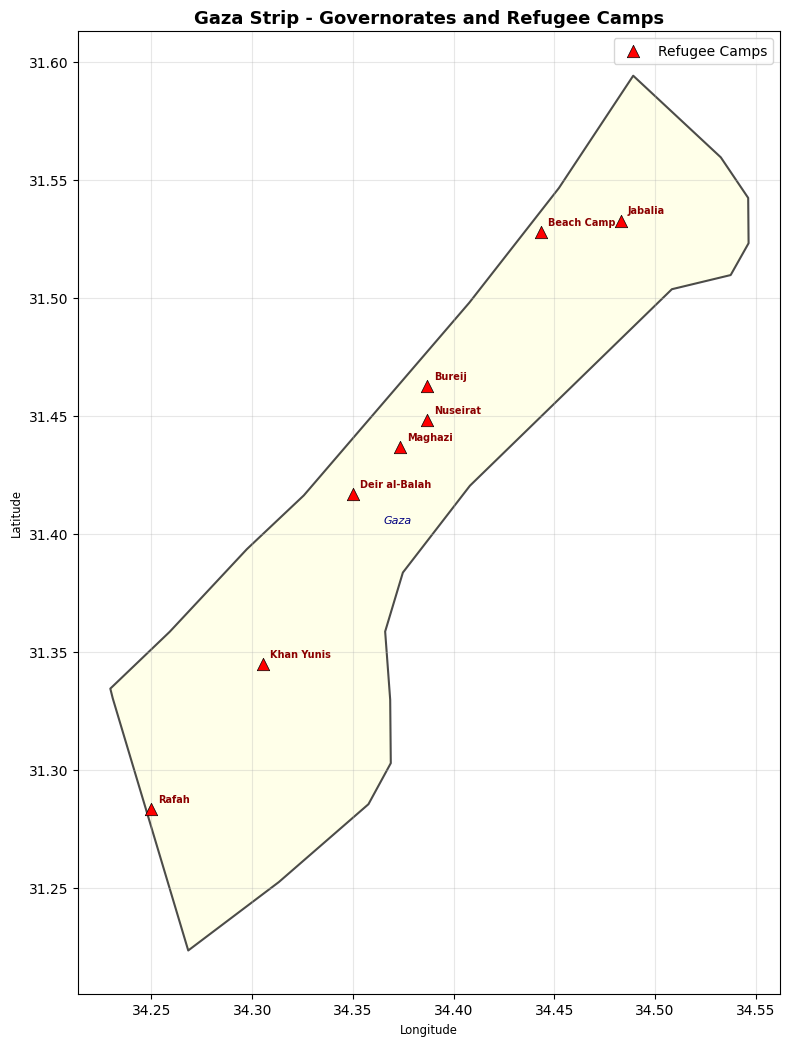

In [12]:
fig, ax = plt.subplots(figsize=(8, 12))

# Plot governorates
gaza.plot(
    ax=ax,
    edgecolor='black',
    linewidth=1.5,
    facecolor='lightyellow',
    alpha=0.7
)

# Plot refugee camps
camps.plot(
    ax=ax,
    color='red',
    markersize=80,
    marker='^',          # Triangle marker
    edgecolor='black',
    linewidth=0.5,
    zorder=5,
    label='Refugee Camps'
)

# Label each camp
for _, row in camps.iterrows():
    ax.annotate(
        row["name"],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=7,
        color='darkred',
        fontweight='bold'
    )

# Label each governorate
for _, row in gaza.iterrows():
    ax.annotate(
        row["NAME_1"],
        xy=(row["cen_lon"], row["cen_lat"]),
        ha='center',
        fontsize=8,
        fontstyle='italic',
        color='navy'
    )

ax.set_title("Gaza Strip - Governorates and Refugee Camps",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("output/gaza_camps_governorates.png", dpi=150, bbox_inches='tight')
plt.show()

# Part B: Loading and Exploring Algeria Data

## Exercise B1: Load Algeria Wilayas

In [13]:
# Load Algeria administrative boundaries (Level 1 = wilayas)
algeria = load_gadm("https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_DZA_1.json")

print("=== Algeria Data Overview ===")
print(f"Shape: {algeria.shape}")
print(f"Columns: {list(algeria.columns)}")
print(f"CRS: {algeria.crs}")
print()

# Total bounds
minx, miny, maxx, maxy = algeria.total_bounds
print("Total bounds:")
print(f"  West:  {minx:.4f}")
print(f"  South: {miny:.4f}")
print(f"  East:  {maxx:.4f}")
print(f"  North: {maxy:.4f}")

=== Algeria Data Overview ===
Shape: (48, 12)
Columns: ['GID_1', 'GID_0', 'COUNTRY', 'NAME_1', 'VARNAME_1', 'NL_NAME_1', 'TYPE_1', 'ENGTYPE_1', 'CC_1', 'HASC_1', 'ISO_1', 'geometry']
CRS: EPSG:4326

Total bounds:
  West:  -8.6739
  South: 18.9602
  East:  11.9874
  North: 37.0887


## Exercise B2: Print All Wilaya Names
Note: the lab title says 58 wilayas, but the number of rows depends on the GADM version (GADM 4.1 may contain 48). The code prints the **actual** count from the data, so mention the real number in your report.

In [14]:
wilaya_names = algeria["NAME_1"].sort_values().tolist()
print(f"=== All {len(wilaya_names)} Wilayas of Algeria (as found in the dataset) ===")
for i, name in enumerate(wilaya_names, 1):
    print(f"  {i:2d}. {name}")
print(f"\nTotal: {len(wilaya_names)} wilayas")

=== All 48 Wilayas of Algeria (as found in the dataset) ===
   1. Adrar
   2. Alger
   3. Annaba
   4. AïnDefla
   5. AïnTémouchent
   6. Batna
   7. Biskra
   8. Blida
   9. BordjBouArréridj
  10. Bouira
  11. Boumerdès
  12. Béchar
  13. Béjaïa
  14. Chlef
  15. Constantine
  16. Djelfa
  17. ElBayadh
  18. ElOued
  19. ElTarf
  20. Ghardaïa
  21. Guelma
  22. Illizi
  23. Jijel
  24. Khenchela
  25. Laghouat
  26. M'Sila
  27. Mascara
  28. Mila
  29. Mostaganem
  30. Médéa
  31. Naâma
  32. Oran
  33. Ouargla
  34. OumelBouaghi
  35. Relizane
  36. Saïda
  37. SidiBelAbbès
  38. Skikda
  39. SoukAhras
  40. Sétif
  41. Tamanghasset
  42. Tiaret
  43. Tindouf
  44. Tipaza
  45. Tissemsilt
  46. TiziOuzou
  47. Tlemcen
  48. Tébessa

Total: 48 wilayas


## Exercise B3: Calculate Area in km2
Same method as A4, with **UTM zone 31N (EPSG:32631)** as specified by the lab. (Algeria spans several UTM zones, so areas far from zone 31 are only approximate; an equal-area projection would be more accurate, but we follow the lab.)

In [15]:
# Reproject to UTM Zone 31N (EPSG:32631) for area calculation
algeria_utm = algeria.to_crs("EPSG:32631")

algeria["area_m2"] = algeria_utm.geometry.area
algeria["area_km2"] = algeria["area_m2"] / 1e6

# Display all areas sorted
print("=== Wilaya Areas (km2) ===")
area_table = algeria[["NAME_1", "area_km2"]].sort_values("area_km2", ascending=False)
print(area_table.to_string(index=False))
print(f"\nTotal Algeria area: {algeria['area_km2'].sum():,.0f} km2")

=== Wilaya Areas (km2) ===
          NAME_1      area_km2
    Tamanghasset 602070.122555
           Adrar 432884.458776
          Illizi 295480.268711
         Tindouf 164703.024185
          Béchar 162034.992666
         Ouargla 154532.853834
        Ghardaïa  84405.735958
        ElBayadh  71693.644637
          ElOued  43926.157850
          Djelfa  32335.286297
           Naâma  29844.218174
        Laghouat  27531.142300
          Biskra  21506.125313
          Tiaret  20106.979433
          M'Sila  17926.998129
         Tébessa  13309.233636
           Batna  12151.567618
       Khenchela   9596.906050
    SidiBelAbbès   9397.072600
         Tlemcen   9091.879623
           Médéa   8713.301638
           Saïda   6764.718296
           Sétif   6665.443818
    OumelBouaghi   6273.340970
         Mascara   5677.641097
        Relizane   4872.486408
        AïnDefla   4544.478465
          Bouira   4466.082505
       SoukAhras   4241.254818
          Skikda   4156.175508
           C

## Exercise B4: Top 5 Largest and Smallest Wilayas
We sort by area (descending): `head(5)` = largest, `tail(5)` = smallest. The bar charts use `[::-1]` to reverse the lists so the biggest bar appears on top in a horizontal bar chart.

=== 5 Largest Wilayas ===
  Tamanghasset                602,070.12 km2
  Adrar                       432,884.46 km2
  Illizi                      295,480.27 km2
  Tindouf                     164,703.02 km2
  Béchar                      162,034.99 km2

=== 5 Smallest Wilayas ===
  Tipaza                        1,731.85 km2
  Blida                         1,479.50 km2
  Boumerdès                     1,448.80 km2
  Annaba                        1,415.04 km2
  Alger                           766.94 km2


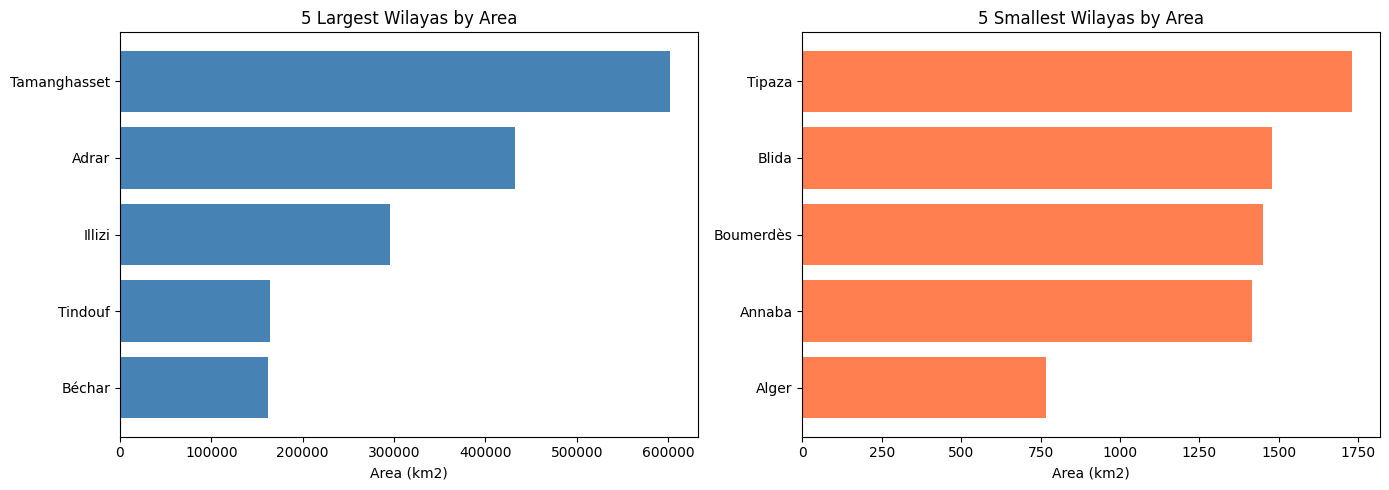

In [16]:
sorted_by_area = algeria.sort_values("area_km2", ascending=False)

print("=== 5 Largest Wilayas ===")
top5 = sorted_by_area.head(5)
for _, row in top5.iterrows():
    print(f"  {row['NAME_1']:25s} {row['area_km2']:>12,.2f} km2")

print()
print("=== 5 Smallest Wilayas ===")
bottom5 = sorted_by_area.tail(5)
for _, row in bottom5.iterrows():
    print(f"  {row['NAME_1']:25s} {row['area_km2']:>12,.2f} km2")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top5_names = top5["NAME_1"].tolist()
top5_areas = top5["area_km2"].tolist()
axes[0].barh(top5_names[::-1], top5_areas[::-1], color='steelblue')
axes[0].set_title("5 Largest Wilayas by Area")
axes[0].set_xlabel("Area (km2)")

bottom5_names = bottom5["NAME_1"].tolist()
bottom5_areas = bottom5["area_km2"].tolist()
axes[1].barh(bottom5_names[::-1], bottom5_areas[::-1], color='coral')
axes[1].set_title("5 Smallest Wilayas by Area")
axes[1].set_xlabel("Area (km2)")

plt.tight_layout()
plt.savefig("output/algeria_area_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

## Exercise B5: Create Major Cities GeoDataFrame
Same technique as A7 (points from coordinates), with an extra `population` attribute column.

In [17]:
cities_data = {
    "name": ["Algiers", "Oran", "Constantine", "Annaba", "Sidi Bel Abbes"],
    "latitude":  [36.7538, 35.6969, 36.3650, 36.9000, 35.1903],
    "longitude": [3.0588, -0.6331, 6.6147, 7.7667, -0.6309],
    "population": [3500000, 1560000, 938475, 640000, 340000]
}

cities = gpd.GeoDataFrame(
    cities_data,
    geometry=gpd.points_from_xy(
        cities_data["longitude"],
        cities_data["latitude"]
    ),
    crs="EPSG:4326"
)

print("=== Major Algerian Cities ===")
print(cities[["name", "latitude", "longitude", "population"]].to_string(index=False))

=== Major Algerian Cities ===
          name  latitude  longitude  population
       Algiers   36.7538     3.0588     3500000
          Oran   35.6969    -0.6331     1560000
   Constantine   36.3650     6.6147      938475
        Annaba   36.9000     7.7667      640000
Sidi Bel Abbes   35.1903    -0.6309      340000


## Exercise B6: Plot Wilayas with Cities Overlay
`column="area_km2"` + `cmap="YlOrRd"` makes a **choropleth** (polygons coloured by value). The cities are drawn above it as blue stars.

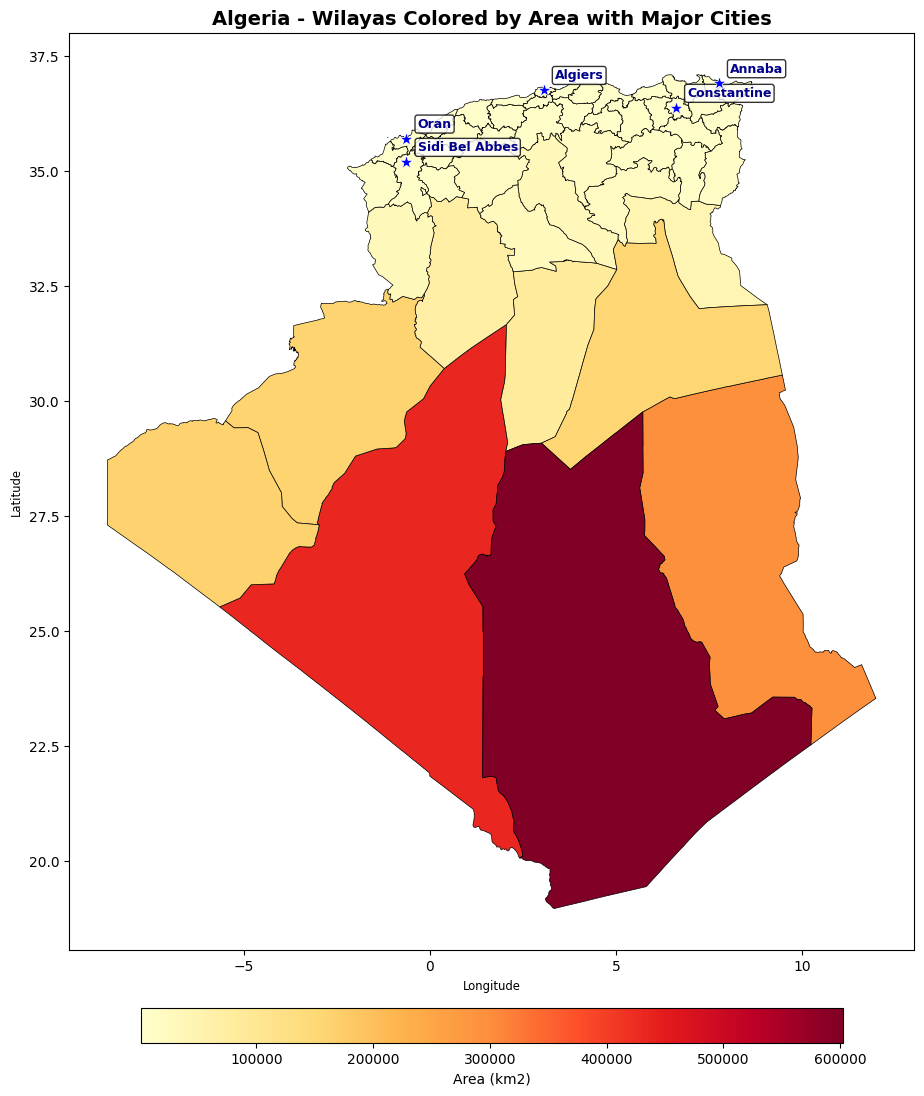

In [18]:
fig, ax = plt.subplots(figsize=(12, 12))

# Plot wilayas colored by area
algeria.plot(
    ax=ax,
    column="area_km2",
    cmap="YlOrRd",
    edgecolor='black',
    linewidth=0.5,
    legend=True,
    legend_kwds={
        'label': 'Area (km2)',
        'orientation': 'horizontal',
        'shrink': 0.6,
        'pad': 0.05
    }
)

# Plot cities
cities.plot(
    ax=ax,
    color='blue',
    markersize=100,
    marker='*',
    edgecolor='white',
    linewidth=0.5,
    zorder=5
)

# Label cities
for _, row in cities.iterrows():
    ax.annotate(
        row["name"],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(8, 8),
        textcoords='offset points',
        fontsize=9,
        fontweight='bold',
        color='darkblue',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8)
    )

ax.set_title("Algeria - Wilayas Colored by Area with Major Cities",
             fontsize=14, fontweight='bold')
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.savefig("output/algeria_wilayas_cities.png", dpi=150, bbox_inches='tight')
plt.show()

## Exercise B7: Export to GeoPackage
A GeoPackage (`.gpkg`) is a single file that can hold **several layers**. We write `wilayas` and `cities` as two layers of the same file, then list the layers to verify. (The old file is removed first so re-running the notebook always starts clean.)

In [19]:
gpkg_path = "output/algeria_data.gpkg"
if os.path.exists(gpkg_path):
    os.remove(gpkg_path)

# Save wilayas to GeoPackage
algeria.to_file(gpkg_path, layer="wilayas", driver="GPKG")

# Save cities to the same GeoPackage (as a separate layer)
cities.to_file(gpkg_path, layer="cities", driver="GPKG")

print(f"Data exported to {gpkg_path}")
print("Layers: 'wilayas', 'cities'")

# Verify by listing layers
print(f"Layers in GeoPackage: {list_layers(gpkg_path)}")

Data exported to output/algeria_data.gpkg
Layers: 'wilayas', 'cities'
Layers in GeoPackage: ['wilayas', 'cities']


# Part C: Format Conversion

## Exercise C1: Save Gaza Data in Multiple Formats
Three common vector formats:
- **GeoJSON**: text, human-readable, always EPSG:4326.
- **Shapefile**: old standard made of several files (`.shp .shx .dbf .prj`), column names limited to 10 characters.
- **GeoPackage**: modern single-file SQLite database, supports many layers.

In [20]:
# Save Gaza governorates in 3 formats
gaza.to_file("output/gaza_governorates.geojson", driver="GeoJSON")
gaza.to_file("output/gaza_governorates.shp")
gaza.to_file("output/gaza_governorates.gpkg", layer="governorates", driver="GPKG")

# Save camps in 3 formats
camps.to_file("output/gaza_camps.geojson", driver="GeoJSON")
camps.to_file("output/gaza_camps.shp")
camps.to_file("output/gaza_camps.gpkg", layer="camps", driver="GPKG")

print("Gaza data saved in GeoJSON, Shapefile, and GeoPackage formats.")

Gaza data saved in GeoJSON, Shapefile, and GeoPackage formats.


## Exercise C2: Save Algeria Data in Multiple Formats

In [21]:
# Save Algeria wilayas in 3 formats
algeria.to_file("output/algeria_wilayas.geojson", driver="GeoJSON")
algeria.to_file("output/algeria_wilayas.shp")
algeria.to_file("output/algeria_wilayas.gpkg", layer="wilayas", driver="GPKG")

# Save cities in 3 formats
cities.to_file("output/algeria_cities.geojson", driver="GeoJSON")
cities.to_file("output/algeria_cities.shp")
cities.to_file("output/algeria_cities.gpkg", layer="cities", driver="GPKG")

print("Algeria data saved in GeoJSON, Shapefile, and GeoPackage formats.")

Algeria data saved in GeoJSON, Shapefile, and GeoPackage formats.


## Exercise C3: Compare File Sizes
A Shapefile is really a group of files, so the helper adds up all its components before comparing.

In [22]:
def get_file_size(path):
    # Return file size in KB. For shapefiles, sum all component files.
    if path.endswith('.shp'):
        base = path[:-4]
        extensions = ['.shp', '.dbf', '.shx', '.prj', '.cpg']
        total = 0
        for ext in extensions:
            fpath = base + ext
            if os.path.exists(fpath):
                total += os.path.getsize(fpath)
        return total / 1024
    else:
        return os.path.getsize(path) / 1024

# Compare Gaza files
print("=== Gaza Governorates - File Size Comparison ===")
formats = {
    "GeoJSON":    "output/gaza_governorates.geojson",
    "Shapefile":  "output/gaza_governorates.shp",
    "GeoPackage": "output/gaza_governorates.gpkg"
}
for fmt, path in formats.items():
    size = get_file_size(path)
    print(f"  {fmt:12s}: {size:8.1f} KB")

print()

# Compare Algeria files
print("=== Algeria Wilayas - File Size Comparison ===")
formats_dz = {
    "GeoJSON":    "output/algeria_wilayas.geojson",
    "Shapefile":  "output/algeria_wilayas.shp",
    "GeoPackage": "output/algeria_wilayas.gpkg"
}
for fmt, path in formats_dz.items():
    size = get_file_size(path)
    print(f"  {fmt:12s}: {size:8.1f} KB")

=== Gaza Governorates - File Size Comparison ===
  GeoJSON     :      1.1 KB
  Shapefile   :      2.2 KB
  GeoPackage  :     96.0 KB

=== Algeria Wilayas - File Size Comparison ===
  GeoJSON     :    377.3 KB
  Shapefile   :    320.1 KB
  GeoPackage  :    412.0 KB


## Exercise C4: Reload and Verify Consistency
We read the three Gaza files back and check that they have the same number of rows, the same CRS and the same geometries (compared through their areas). The Algeria files are checked for rows and CRS.

In [23]:
# Reload Gaza from each format and compare
gaza_geojson = gpd.read_file("output/gaza_governorates.geojson")
gaza_shp = gpd.read_file("output/gaza_governorates.shp")
gaza_gpkg = gpd.read_file("output/gaza_governorates.gpkg", layer="governorates")

print("=== Verification: Gaza Data Consistency ===")
print(f"GeoJSON    - Rows: {len(gaza_geojson)}, CRS: {gaza_geojson.crs.to_epsg()}, "
      f"Columns: {len(gaza_geojson.columns)}")
print(f"Shapefile  - Rows: {len(gaza_shp)}, CRS: {gaza_shp.crs.to_epsg()}, "
      f"Columns: {len(gaza_shp.columns)}")
print(f"GeoPackage - Rows: {len(gaza_gpkg)}, CRS: {gaza_gpkg.crs.to_epsg()}, "
      f"Columns: {len(gaza_gpkg.columns)}")

# Check geometry equality
print()
print("Geometry consistency check:")
for i in range(len(gaza_geojson)):
    geojson_area = gaza_geojson.geometry.iloc[i].area
    shp_area = gaza_shp.geometry.iloc[i].area
    gpkg_area = gaza_gpkg.geometry.iloc[i].area
    match = np.isclose(geojson_area, shp_area) and np.isclose(geojson_area, gpkg_area)
    print(f"  Row {i}: Areas match = {match}")

# Reload Algeria and verify
algeria_geojson = gpd.read_file("output/algeria_wilayas.geojson")
algeria_shp = gpd.read_file("output/algeria_wilayas.shp")
algeria_gpkg = gpd.read_file("output/algeria_wilayas.gpkg", layer="wilayas")

print()
print("=== Verification: Algeria Data Consistency ===")
print(f"GeoJSON    - Rows: {len(algeria_geojson)}, CRS: {algeria_geojson.crs.to_epsg()}")
print(f"Shapefile  - Rows: {len(algeria_shp)}, CRS: {algeria_shp.crs.to_epsg()}")
print(f"GeoPackage - Rows: {len(algeria_gpkg)}, CRS: {algeria_gpkg.crs.to_epsg()}")

# Note: Shapefile truncates column names to 10 characters
print()
print("Column name comparison (note Shapefile truncation):")
print(f"  GeoJSON columns:    {sorted(gaza_geojson.columns.tolist())}")
print(f"  Shapefile columns:  {sorted(gaza_shp.columns.tolist())}")
print(f"  GeoPackage columns: {sorted(gaza_gpkg.columns.tolist())}")

=== Verification: Gaza Data Consistency ===
GeoJSON    - Rows: 1, CRS: 4326, Columns: 16
Shapefile  - Rows: 1, CRS: 4326, Columns: 16
GeoPackage - Rows: 1, CRS: 4326, Columns: 16

Geometry consistency check:
  Row 0: Areas match = True

=== Verification: Algeria Data Consistency ===
GeoJSON    - Rows: 48, CRS: 4326
Shapefile  - Rows: 48, CRS: 4326
GeoPackage - Rows: 48, CRS: 4326

Column name comparison (note Shapefile truncation):
  GeoJSON columns:    ['CC_1', 'COUNTRY', 'ENGTYPE_1', 'GID_0', 'GID_1', 'HASC_1', 'ISO_1', 'NAME_1', 'NL_NAME_1', 'TYPE_1', 'VARNAME_1', 'area_km2', 'area_m2', 'cen_lat', 'cen_lon', 'geometry']
  Shapefile columns:  ['CC_1', 'COUNTRY', 'ENGTYPE_1', 'GID_0', 'GID_1', 'HASC_1', 'ISO_1', 'NAME_1', 'NL_NAME_1', 'TYPE_1', 'VARNAME_1', 'area_km2', 'area_m2', 'cen_lat', 'cen_lon', 'geometry']
  GeoPackage columns: ['CC_1', 'COUNTRY', 'ENGTYPE_1', 'GID_0', 'GID_1', 'HASC_1', 'ISO_1', 'NAME_1', 'NL_NAME_1', 'TYPE_1', 'VARNAME_1', 'area_km2', 'area_m2', 'cen_lat', 'c

# Part D: Geometry Operations

## Exercise D1: Gaza Geometry Operations
- `dissolve()` merges all governorates into **one** geometry (the whole Strip). We keep only the geometry column for it so no attribute aggregation can fail.
- The **convex hull** is the smallest convex polygon containing the shape (like a rubber band around it).
- Ratio actual area / hull area measures how "compact" the shape is (100% = already convex).

In [24]:
# Total area of Gaza Strip
total_area_km2 = gaza["area_km2"].sum()
print("=== Gaza Strip Geometry Operations ===")
print(f"Total area: {total_area_km2:.2f} km2")

# Centroid of entire strip (dissolve all governorates into one)
gaza_dissolved = gaza[["geometry"]].dissolve()
gaza_centroid = (gaza_dissolved.to_crs("EPSG:32636").geometry.centroid
                 .to_crs("EPSG:4326").iloc[0])
print(f"Centroid of entire strip: Lat={gaza_centroid.y:.4f}, Lon={gaza_centroid.x:.4f}")

# Convex hull of entire strip
gaza_hull = gaza_dissolved.geometry.convex_hull.iloc[0]
print(f"Convex hull area (sq degrees): {gaza_hull.area:.6f}")

# Calculate convex hull area in km2 (reproject first)
gaza_hull_gdf = gpd.GeoDataFrame(geometry=[gaza_hull], crs="EPSG:4326")
gaza_hull_utm = gaza_hull_gdf.to_crs("EPSG:32636")
hull_area_km2 = gaza_hull_utm.geometry.area.iloc[0] / 1e6
print(f"Convex hull area: {hull_area_km2:.2f} km2")
print(f"Ratio (actual/convex hull): {total_area_km2 / hull_area_km2:.2%}")

=== Gaza Strip Geometry Operations ===
Total area: 342.48 km2
Centroid of entire strip: Lat=31.4043, Lon=34.3723
Convex hull area (sq degrees): 0.043706
Convex hull area: 460.89 km2
Ratio (actual/convex hull): 74.31%


## Exercise D2: Algeria Geometry Operations
We find the northernmost/southernmost wilaya using the centroid latitude (`idxmax` / `idxmin` return the row label of the max / min), then compare the real area to the convex hull area.

In [25]:
print("=== Algeria Geometry Operations ===")

# Centroids computed in a projected CRS, then converted back to lat/lon
alg_centroids = algeria_utm.geometry.centroid.to_crs("EPSG:4326")
algeria["cen_lat"] = alg_centroids.y.values
algeria["cen_lon"] = alg_centroids.x.values

northernmost = algeria.loc[algeria["cen_lat"].idxmax()]
southernmost = algeria.loc[algeria["cen_lat"].idxmin()]

print(f"Northernmost wilaya: {northernmost['NAME_1']} "
      f"(centroid lat: {northernmost['cen_lat']:.4f})")
print(f"Southernmost wilaya: {southernmost['NAME_1']} "
      f"(centroid lat: {southernmost['cen_lat']:.4f})")

# Convex hull of all wilayas
algeria_dissolved = algeria[["geometry"]].dissolve()
algeria_hull = algeria_dissolved.geometry.convex_hull.iloc[0]

# Area comparison
algeria_hull_gdf = gpd.GeoDataFrame(geometry=[algeria_hull], crs="EPSG:4326")
algeria_hull_utm = algeria_hull_gdf.to_crs("EPSG:32631")
hull_area = algeria_hull_utm.geometry.area.iloc[0] / 1e6
actual_area = algeria["area_km2"].sum()

print(f"\nActual total area: {actual_area:,.0f} km2")
print(f"Convex hull area:  {hull_area:,.0f} km2")
print(f"Compactness ratio: {actual_area / hull_area:.2%}")

=== Algeria Geometry Operations ===
Northernmost wilaya: Annaba (centroid lat: 36.8381)
Southernmost wilaya: Tamanghasset (centroid lat: 23.8716)

Actual total area: 2,316,663 km2
Convex hull area:  2,668,849 km2
Compactness ratio: 86.80%


## Exercise D3: Side-by-Side Convex Hull Plot
Each panel shows the shape, its convex hull (red dashed outline) and the centroid of the whole country (red star).

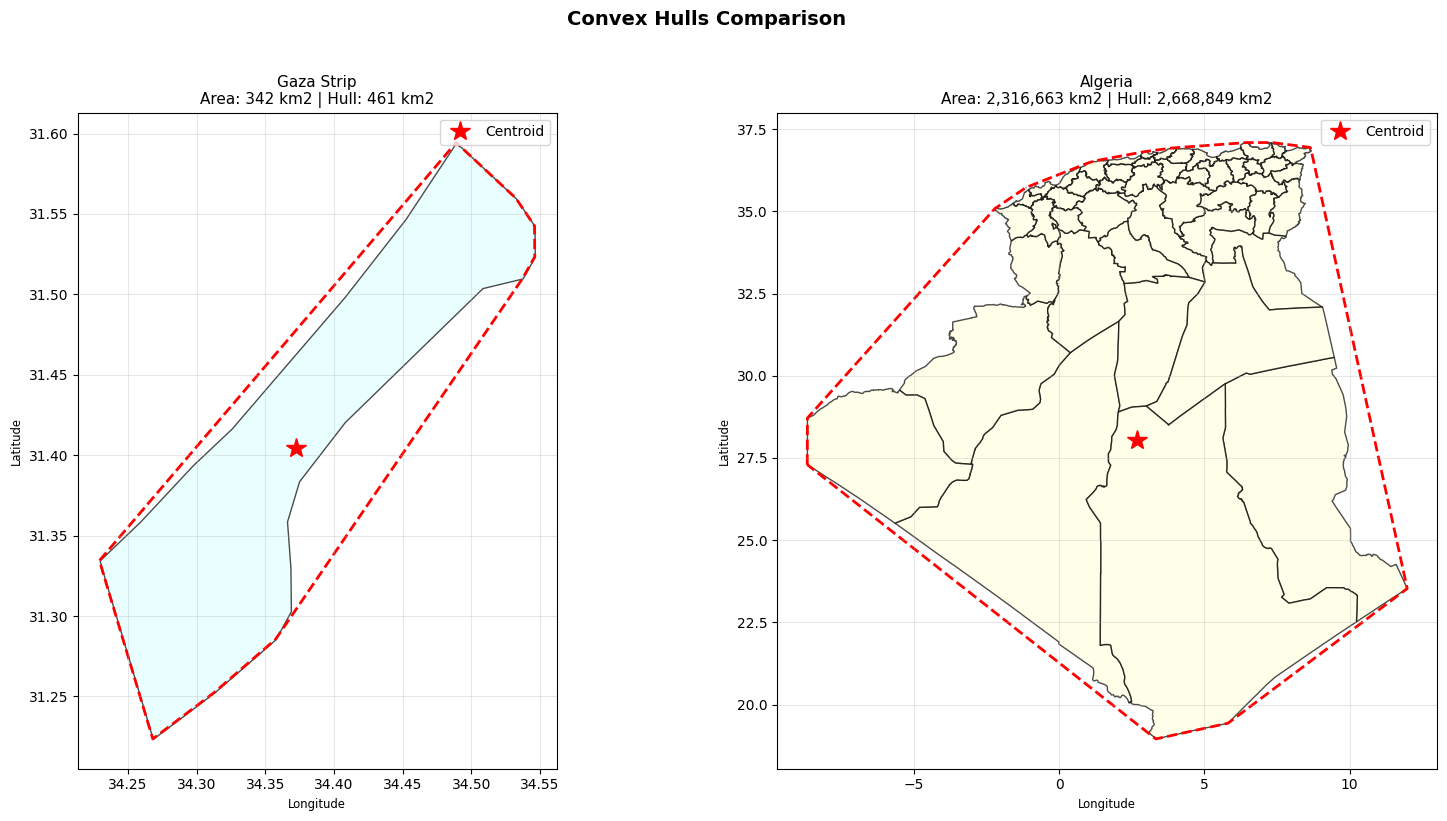

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# --- Gaza ---
ax1 = axes[0]
gaza.plot(ax=ax1, edgecolor='black', facecolor='lightcyan', alpha=0.7)
gpd.GeoSeries([gaza_hull], crs="EPSG:4326").plot(
    ax=ax1, edgecolor='red', facecolor='none', linewidth=2, linestyle='--'
)
ax1.plot(gaza_centroid.x, gaza_centroid.y, 'r*', markersize=15, label='Centroid')
ax1.set_title(f"Gaza Strip\nArea: {total_area_km2:.0f} km2 | "
              f"Hull: {hull_area_km2:.0f} km2", fontsize=11)
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_xlabel("Longitude")
ax1.set_ylabel("Latitude")

# --- Algeria ---
ax2 = axes[1]
algeria.plot(ax=ax2, edgecolor='black', facecolor='lightyellow', alpha=0.7)
gpd.GeoSeries([algeria_hull], crs="EPSG:4326").plot(
    ax=ax2, edgecolor='red', facecolor='none', linewidth=2, linestyle='--'
)
algeria_centroid = (algeria_dissolved.to_crs("EPSG:32631").geometry.centroid
                    .to_crs("EPSG:4326").iloc[0])
ax2.plot(algeria_centroid.x, algeria_centroid.y, 'r*', markersize=15, label='Centroid')
ax2.set_title(f"Algeria\nArea: {actual_area:,.0f} km2 | "
              f"Hull: {hull_area:,.0f} km2", fontsize=11)
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")

plt.suptitle("Convex Hulls Comparison", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("output/convex_hulls_comparison.png", dpi=150, bbox_inches='tight')
plt.show()